# Dynamical Decoupling

Python companion to the AMO Toolkit page [Dynamical Decoupling](https://amotoolkit.com/pages/dd-playground.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/dd-playground.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Filter functions
A qubit dephased by classical noise with spectrum S(ω) keeps coherence $W = e^{-\chi}$ with
$\chi(T) = \frac{1}{2\pi}\int_0^\infty S(\omega)\,|\tilde Y(\omega,T)|^2\,d\omega$,
where $\tilde Y$ is the Fourier transform of the switching function (±1, flipped by each π pulse). For N pulses at CPMG times $t_k=(2k-1)T/2N$ there is a closed form (Cywiński et al., PRB 77, 174509 (2008)). T₂ is defined by χ(T₂) = 1.

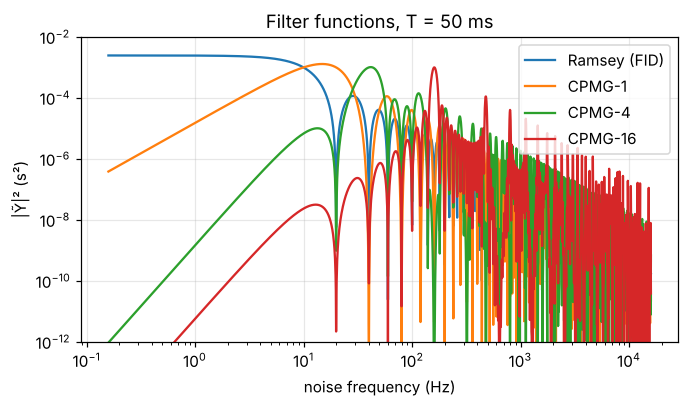

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def cpmg_times(N, T):
    return (2 * np.arange(N) + 1) * T / (2 * N)

def Y2(w, pulses, T):
    """|Ỹ(ω,T)|² summed segment by segment (any pulse times)."""
    times = np.concatenate(([0], np.sort(pulses), [T]))
    w = np.atleast_1d(w)[:, None]
    sign = np.where(np.arange(len(times) - 1) % 2 == 0, 1.0, -1.0)
    t1, t2 = times[:-1], times[1:]
    re = np.sum(sign * (np.sin(w * t2) - np.sin(w * t1)) / w, axis=1)
    im = np.sum(sign * (np.cos(w * t1) - np.cos(w * t2)) / w, axis=1)
    return re**2 + im**2

def Y2_cpmg(w, N, T):
    c = np.cos(w * T / (2 * N))
    h = np.sin(w * T / 2) if N % 2 == 0 else np.cos(w * T / 2)
    out = 16 * np.sin(w * T / (4 * N)) ** 4 * h**2 / (w**2 * c**2)
    bad = (np.abs(c) < 1e-4) | (w * T < 1e-6)
    if bad.any(): out[bad] = Y2(w[bad], cpmg_times(N, T), T)
    return out

T = 0.05
w = np.logspace(0, 5, 2000)
for N in (0, 1, 4, 16):
    F = Y2(w, [], T) if N == 0 else Y2_cpmg(w, N, T)
    plt.loglog(w / (2 * np.pi), F, label="Ramsey (FID)" if N == 0 else f"CPMG-{N}")
plt.xlabel("noise frequency (Hz)"); plt.ylabel("|Ỹ|² (s²)"); plt.ylim(1e-12, 1e-2); plt.legend(); plt.title("Filter functions, T = 50 ms")

CPMG-N is a band-pass filter centred at $\omega_c \approx \pi N/T$, i.e. $f_c = N/2T$. That is the basis of noise spectroscopy: step N and T to scan $f_c$ across the spectrum.

## 2. T₂ against the number of pulses
Noise $S(\omega) = A\,\omega^{-\alpha}$, with A set so that the free-induction decay gives the chosen T₂*. Then bisect for χ(T₂) = 1 with N pulses. The page's defaults: T₂* = 10 ms, α = 1.

α = 1: N=1: 3.11×, N=2: 4.13×, N=4: 5.72×, N=8: 8.01×, N=16: 11.25×, N=64: 22.44×, N=256: 44.79×

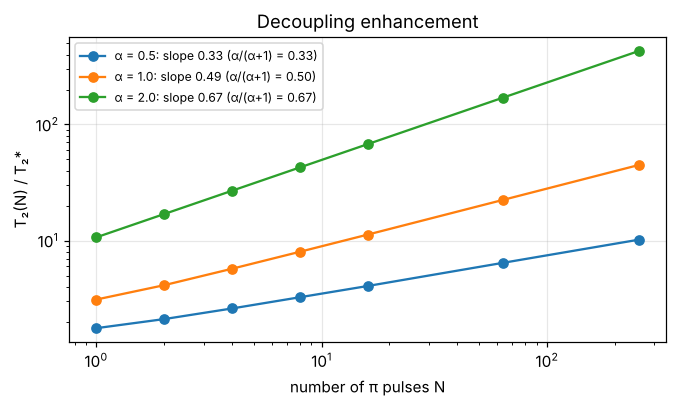

In [2]:
def chi(T, N, alpha, A):
    Nn = max(N, 1)
    wmin, wmax, Nw = np.pi * 0.001 / T, np.pi * 500 * Nn / T, max(600, 60 * Nn)
    dlw = np.log(wmax / wmin) / Nw
    w = wmin * np.exp((np.arange(Nw) + 0.5) * dlw)
    F = Y2(w, [], T) if N == 0 else Y2_cpmg(w, N, T)
    return np.sum(A * w**-alpha * F * w * dlw) / (2 * np.pi)

def find_A(T2s, alpha):
    lo, hi = 1e-40, 1e40
    for _ in range(80):
        mid = np.sqrt(lo * hi)
        if chi(T2s, 0, alpha, mid) < 1: lo = mid
        else: hi = mid
    return np.sqrt(lo * hi)

def find_T2(N, alpha, A, T2s):
    lo, hi = T2s * 0.5, T2s * 20000
    if chi(hi, N, alpha, A) < 1: hi = T2s * 1e6
    for _ in range(80):
        T = np.sqrt(lo * hi)
        if chi(T, N, alpha, A) < 1: lo = T
        else: hi = T
    return np.sqrt(lo * hi)

T2s, Ns = 0.010, [1, 2, 4, 8, 16, 64, 256]
res = {}
for alpha in (0.5, 1.0, 2.0):
    A = find_A(T2s, alpha)
    enh = np.array([find_T2(N, alpha, A, T2s) / T2s for N in Ns]); res[alpha] = enh
    slope = np.log(enh[-1] / enh[2]) / np.log(256 / 4)
    plt.loglog(Ns, enh, "o-", label=f"α = {alpha}: slope {slope:.2f} (α/(α+1) = {alpha/(alpha+1):.2f})")
plt.xlabel("number of π pulses N"); plt.ylabel("T₂(N) / T₂*"); plt.legend(fontsize=8); plt.title("Decoupling enhancement")
print("α = 1:", ", ".join(f"N={n}: {e:.2f}×" for n, e in zip(Ns, res[1.0])))

**Read with care:** this is classical, Gaussian, pure-dephasing noise with ideal instantaneous pulses. Real pulses have errors (that is what XY-4/8/16 address), and T₁ processes are not refocused at all.

## 3. Check against the page

In [3]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

e = res[1.0]
ours = dict(N1=e[0], N16=e[4], N256=e[6], slope=np.log(e[6] / e[2]) / np.log(64))
DECIMALS = dict(N1=2, N16=2, N256=2, slope=2)
page = dict(N1=3.11, N16=11.25, N256=44.79, slope=0.49)
check(ours, page)

          N1: notebook 3.106        page 3.11       OK
         N16: notebook 11.25        page 11.25      OK
        N256: notebook 44.79        page 44.79      OK
       slope: notebook 0.4949       page 0.49       OK
All values match the page.